## <span style="color:red"> Load Datasets </span>

In [1]:
import pandas as pd
import numpy as np
import os

DATA_PATH = "../data/raw/"

sales = pd.read_csv(DATA_PATH + "sales.csv")
catalog = pd.read_csv(DATA_PATH + "catalog.csv")
stores = pd.read_csv(DATA_PATH + "stores.csv")
price_history = pd.read_csv(DATA_PATH + "price_history.csv")
discounts_history = pd.read_csv(DATA_PATH + "discounts_history.csv")
markdowns = pd.read_csv(DATA_PATH + "markdowns.csv")
actual_matrix = pd.read_csv(DATA_PATH + "actual_matrix.csv")
online = pd.read_csv(DATA_PATH + "online.csv")

## <span style="color:red">Dataset Summary </span>

In [4]:
files = {
    "sales": sales,
    "catalog": catalog,
    "stores": stores,
    "price_history": price_history,
    "discounts": discounts_history,
    "markdowns": markdowns,
    "actual_matrix": actual_matrix,
    "online": online
}

for name, df in files.items():
    print("\n")
    print("--" * 70)
    print(name.upper())
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)



--------------------------------------------------------------------------------------------------------------------------------------------
SALES
Shape: (7432685, 7)

Columns:
['Unnamed: 0', 'date', 'item_id', 'quantity', 'price_base', 'sum_total', 'store_id']

Data types:
Unnamed: 0      int64
date           object
item_id        object
quantity      float64
price_base    float64
sum_total     float64
store_id        int64
dtype: object


--------------------------------------------------------------------------------------------------------------------------------------------
CATALOG
Shape: (219810, 9)

Columns:
['Unnamed: 0', 'item_id', 'dept_name', 'class_name', 'subclass_name', 'item_type', 'weight_volume', 'weight_netto', 'fatness']

Data types:
Unnamed: 0         int64
item_id           object
dept_name         object
class_name        object
subclass_name     object
item_type         object
weight_volume    float64
weight_netto     float64
fatness          float64
dtype: obj

## <span style="color:red">Check Missing & Duplicate Values </span>

In [5]:
for name, df in files.items():
    print("=" * 60)
    print(name.upper())

    missing = df.isnull().sum()
    missing_percent = (missing / len(df)) * 100

    result = pd.DataFrame({
        "Missing Values": missing,
        "Missing %": missing_percent.round(2)
    })

    if missing.sum() == 0:
        print("No missing values")
    else:
        print(result)

SALES
No missing values
CATALOG
               Missing Values  Missing %
Unnamed: 0                  0       0.00
item_id                     0       0.00
dept_name                   0       0.00
class_name                  0       0.00
subclass_name               0       0.00
item_type              176224      80.17
weight_volume          136858      62.26
weight_netto           170853      77.73
fatness                212598      96.72
STORES
No missing values
PRICE_HISTORY
No missing values
DISCOUNTS
                         Missing Values  Missing %
Unnamed: 0                            0       0.00
date                                  0       0.00
item_id                               0       0.00
sale_price_before_promo               0       0.00
sale_price_time_promo                 0       0.00
promo_type_code                  317846       8.48
doc_id                                0       0.00
number_disc_day                       0       0.00
store_id                        

## <span style="color:red"> Check Duplicates </span>

In [6]:
for name, df in files.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

sales: 0 duplicate rows
catalog: 0 duplicate rows
stores: 0 duplicate rows
price_history: 0 duplicate rows
discounts: 0 duplicate rows
markdowns: 0 duplicate rows
actual_matrix: 0 duplicate rows
online: 0 duplicate rows


# <span style="color:red"> Viewing Datasets </span>

In [7]:
sales

,Unnamed: 0,date,item_id,quantity,price_base,sum_total,store_id
0,0,2023-08-04,293375605257,1.000,47.86,47.86,1
1,1,2023-08-04,a66fdf2c0ae7,3.000,49.60,148.80,1
2,2,2023-08-04,daa46ef49b7a,0.822,379.00,311.54,1
3,3,2023-08-04,a3b49c1bf758,1.000,129.00,129.00,1
4,4,2023-08-04,ab611c5cef62,7.000,79.90,559.30,1
...,...,...,...,...,...,...,...
7432680,21739585,2024-09-26,542f4875a846,2.000,419.90,839.80,4
7432681,21739586,2024-09-26,3c7435256b1f,2.000,299.90,599.80,4
7432682,21739587,2024-09-26,87b794255afc,6.000,499.90,2999.40,4
7432683,21739588,2024-09-26,0a832c545a6a,1.000,189.90,189.90,4


In [8]:
catalog

,Unnamed: 0,item_id,dept_name,class_name,subclass_name,item_type,weight_volume,weight_netto,fatness
0,0,da17e2d5feda,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,БУМАЖНАЯ ПРОДУКЦИЯ,ВЛАЖНЫЕ САЛФЕТКИ,NaN,150.0,NaN,NaN
1,1,614de2b96018,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,30.0,NaN,NaN
2,2,0c1f1f3e3e11,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,NaN,NaN,NaN
3,3,71a7fa99f005,ТОВАРЫ ДЛЯ ДОМА,ПОСУДА,КУХОННАЯ ПОСУДА,NaN,NaN,NaN,NaN
4,4,ec1bd4d59fe9,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,30.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
219805,219806,a8eae2f5974a,СЛАДКИЕ МУЧНЫЕ ИЗДЕЛИЯ,ПЕЧЕНЬЕ,ПЕЧЕНЬЕ ФАСОВАННОЕ,NaN,NaN,NaN,NaN
219806,219807,54a786e4a589,СЛАДКИЕ МУЧНЫЕ ИЗДЕЛИЯ,ПЕЧЕНЬЕ,ПЕЧЕНЬЕ ФАСОВАННОЕ,NaN,NaN,NaN,NaN
219807,219808,a96e686cb2ff,ДЕТСКИЙ МИР,ИГРУШКИ,РАЗВИВАЮЩИЕ ИГРУШКИ,NaN,NaN,NaN,NaN
219808,219809,49cdb76c6eb7,ДЕТСКИЙ МИР,ИГРУШКИ,РАЗВИВАЮЩИЕ ИГРУШКИ,NaN,NaN,NaN,NaN


In [9]:
stores

,Unnamed: 0,store_id,division,format,city,area
0,0,4,Div1,MaxiEuro,City3,1887
1,1,3,Div2,Format-7 express,City2,109
2,2,2,Div2,Format-6,City1,210
3,3,1,Div1,Format-1,City1,1500


In [10]:
price_history

,Unnamed: 0,date,item_id,price,code,store_id
0,0,2023-08-01,4a1f95fe4d4b,499.9,1,1
1,1,2023-08-01,bf43a9d3ae13,0.0,9999999999,1
2,2,2023-08-01,0dd8744decce,129.9,1,1
3,3,2023-08-01,9b38c7e4dba9,136.0,1,1
4,4,2023-08-01,b791e8c9347c,0.0,1,1
...,...,...,...,...,...,...
698621,1885028,2024-09-26,7586d4f4599e,479.9,10,4
698622,1885029,2024-09-26,4b7ea164af56,359.9,31,4
698623,1885030,2024-09-26,c1b874b62220,359.9,10,4
698624,1885031,2024-09-26,c1b874b62220,279.9,29,4


In [15]:
discounts_history

,Unnamed: 0,date,item_id,sale_price_before_promo,sale_price_time_promo,promo_type_code,doc_id,number_disc_day,store_id
0,3648316,2022-08-28,cde97a9ec3ef,729.9,669.9,6.0,89ea9f0c-1c08-11ed-ad4d-005056861040,13.0,1
1,3648317,2022-08-28,2906fbc9e11c,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1
2,3648318,2022-08-28,c48c3a3d8c01,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1
3,3648319,2022-08-28,f85243ca61e6,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1
4,3648320,2022-08-28,27ce75534065,129.9,99.9,NaN,039e85df-1e51-11ed-ad4d-005056861040,11.0,1
...,...,...,...,...,...,...,...,...,...
3746739,11420928,2045-12-31,23b18d1f7da9,59.9,59.9,NaN,baa3d490-5529-11ed-bb91-005056afbcf1,8766.0,4
3746740,11420929,2045-12-31,e5b2b6f57ea7,59.9,59.9,NaN,baa3d490-5529-11ed-bb91-005056afbcf1,8766.0,4
3746741,11420930,2045-12-31,2c007023f650,59.9,59.9,NaN,baa3d490-5529-11ed-bb91-005056afbcf1,8766.0,4
3746742,11420931,2045-12-31,9f716dce9a57,59.9,59.9,NaN,baa3d490-5529-11ed-bb91-005056afbcf1,8766.0,4


In [12]:
markdowns

,Unnamed: 0,date,item_id,normal_price,price,quantity,store_id
0,0,2023-08-01,bc2f82a22e11,189.0,100.0,8.0,1
1,1,2023-08-01,389412076801,179.0,100.0,5.0,1
2,2,2023-08-01,0e39cf5d57c1,149.0,100.0,5.0,1
3,3,2023-08-01,dd94e2bc5601,149.0,100.0,1.0,1
4,4,2023-08-01,e60d890f2812,369.0,270.0,1.0,1
...,...,...,...,...,...,...,...
8974,35033,2024-09-26,07605df7333f,199.0,95.6,1.0,4
8975,35034,2024-09-26,d60184cf6ca5,199.0,119.4,2.0,4
8976,35035,2024-09-26,17abde81f33d,549.0,311.9,1.0,4
8977,35036,2024-09-26,4cf0bb777594,569.0,340.2,2.0,4


In [13]:
actual_matrix

,Unnamed: 0,item_id,date,store_id
0,0,c578da8e8841,2019-10-17,1
1,1,4dd2b686802c,2019-10-17,1
2,2,16ade2e3fca9,2019-10-17,1
3,3,f4eb16dab09e,2019-10-17,1
4,4,ab1384c2af6d,2020-05-31,1
...,...,...,...,...
35197,35197,9c82c0176fc7,2023-12-13,4
35198,35198,0e1be538fe90,2024-07-14,4
35199,35199,19a1bd7fc540,2023-12-13,4
35200,35200,d909b265462e,2023-12-13,4


In [14]:
online

,Unnamed: 0,date,item_id,quantity,price_base,sum_total,store_id
0,0,2023-08-04,4aa8dbe05246,3.000,12.40,37.21,1
1,1,2023-08-04,4e0fbcf99cf9,2.000,56.27,112.54,1
2,2,2023-08-04,2e008b673129,2.000,56.27,112.54,1
3,3,2023-08-04,49db9c973903,1.000,29.94,29.94,1
4,4,2023-08-04,9d6072422e8e,1.000,80.10,80.10,1
...,...,...,...,...,...,...,...
1123407,2350897,2024-09-26,039823e72e87,1.000,121.65,121.65,4
1123408,2350898,2024-09-26,5879ed009378,1.330,127.83,170.01,4
1123409,2350899,2024-09-26,1b7358178593,4.018,41.36,166.19,4
1123410,2350900,2024-09-26,1218d0240db0,2.000,14.63,29.26,4


### <span style="color:navy"> Conclusion - </span>

| File                    | Use?                              | Why?                                                     |
| ----------------------- | --------------------------------- | -------------------------------------------------------- |
| `sales.csv`             | ✅ **Main**                        | Actual historical quantity sold — this is our target     |
| `stores.csv`            | ✅ **Use**                         | Store/branch information                                 |
| `catalog.csv`           | ✅ **Use selectively**             | Product/category information                             |
| `price_history.csv`     | 🟢 **Potentially use**            | Price can influence demand                               |
| `discounts_history.csv` | 🟢 **Potentially use**            | Promotions can influence demand                          |
| `actual_matrix.csv`     | 🟢 **Important for availability** | Helps determine whether a product was actually available |
| `markdowns.csv`         | 🟡 Maybe                          | Additional pricing/markdown information                  |
| `online.csv`            | ❌ **Not initially**               | We are forecasting physical-store demand                 |


# <span style="color:red">Interacting With main dataset -</span>
### <span style="color:green"> sales.csv + stores.csv + catalog.csv </span>

In [ ]:
# Date Analysis

# Make sure date is datetime
sales["date"] = pd.to_datetime(sales["date"])
print("========== DATE INFORMATION ==========")
print("Start date:", sales["date"].min())
print("End date:", sales["date"].max())
print("Unique dates:", sales["date"].nunique())


In [ ]:
# Store Analysis

print("\n========== STORE INFORMATION ==========")
print("Number of stores:", sales["store_id"].nunique())
print("Store IDs:", sorted(sales["store_id"].unique()))

print("\nSales records per store:")
display(sales["store_id"].value_counts().sort_index())

In [ ]:
# Product Analysis

print("========== PRODUCT INFORMATION ==========")
print("Unique products:", sales["item_id"].nunique())

Info = sales.groupby("store_id")["item_id"].nunique().sort_index()
print("\nProducts per store:", Info)

## <span style="color:#C90078"> Store × Product combinations </span>

In [ ]:
store_product = (
    sales.groupby(["store_id", "item_id"])
    .size()
    .reset_index(name="records")
)

print("Total Store × Product combinations:",
      len(store_product))

store_product.head()

In [ ]:
print("Store × Product combinations by store:")
store_product.groupby("store_id").size()


## <span style="color:#C90078"> Check whether multiple records exist for the same day </span>
<span style="color:purple"> We eventually want: ONE ROW = ONE STORE + ONE PRODUCT + ONE DAY     </span> 

<span style="color:navy"> Instead of:</span>   
2024-01-01 | Store 1 | Product 100 | 10    
2024-01-01 | Store 1 | Product 100 | 5    
2024-01-01 | Store 1 | Product 100 | 8  

<span style="color:navy">We want: </span>     
2024-01-01 | Store 1 | Product 100 | 23    


In [ ]:
daily_duplicates = (
    sales.groupby(["date", "store_id", "item_id"])
    .size()
)

print("Total Date × Store × Product combinations:",
      len(daily_duplicates))

print("\nCombinations having multiple records:",
      (daily_duplicates > 1).sum())

print("\nMaximum records for one Date × Store × Product:",
      daily_duplicates.max())

## <span style="color:#C90078"> Check sales quantity </span>

In [ ]:
display(sales["quantity"].describe())
print("\nZero quantity:", (sales["quantity"] == 0).sum())     # No Sales
print("Negative quantity:", (sales["quantity"] < 0).sum())   # Returned Products
print("Positive quantity:", (sales["quantity"] > 0).sum())

In [ ]:
# NEGATIVE QUANTITY

negative_sales = sales[sales["quantity"] < 0]
print("Number of negative records:", len(negative_sales))
negative_sales.sort_values("quantity").head(10)

In [ ]:
# EXTREME VALUES 

print("Largest quantities:")
display(
    sales.nlargest(5, "quantity")[
        ["date", "item_id", "quantity", "price_base", "sum_total", "store_id"]
    ]
)

print("\nSmallest quantities:")
display(
    sales.nsmallest(5, "quantity")[
        ["date", "item_id", "quantity", "price_base", "sum_total", "store_id"]
    ]
)

<span style="color:purple"> **NOTE:** </span>   
**Negative Quantity -**    
1,160 negative records out of 7,432,685    
That's only about 0.016% of the sales records.

**Largest Quantity -**   
At first glance these look like outliers.    
The price is extremely low, which suggests this could be a special type of product or a pricing situation rather than simply a corrupted quantity.

# <span style="color:red"> Understand actual_matrix.csv </span>

__Our sales data tells us:__
"How much was sold."

__But we also need to understand:__
"Was this product actually available at this store on that date?"

Let: **Store 1 + Product A + 2024-05-10**      
Case 1: Product was available → nobody bought it → demand may be 0.    
Case 2: Product wasn't available → we don't know the actual demand.

In [ ]:
actual_matrix.head()

In [ ]:
print("Shape:", actual_matrix.shape)
actual_matrix.dtypes


In [ ]:
print("\nUnique values per column:")

for col in actual_matrix.columns:
    print(col,"→", actual_matrix[col].nunique())

In [ ]:
# Checking whether actual_matrix and sales actually overlap in the same period , so we can merge them

In [ ]:
actual_matrix["date"] = pd.to_datetime(actual_matrix["date"])

print("Actual Matrix date range:")
print("Start:", actual_matrix["date"].min())
print("End:", actual_matrix["date"].max())

print("\nSales date range:")
print("Start:", sales["date"].min())
print("End:", sales["date"].max())

In [ ]:
overlap = actual_matrix[
    (actual_matrix["date"] >= sales["date"].min()) &
    (actual_matrix["date"] <= sales["date"].max())
]

print("Actual Matrix rows within sales period:", len(overlap))

print("Unique dates:", overlap["date"].nunique())
print("Unique products:", overlap["item_id"].nunique())
print("Unique stores:", overlap["store_id"].nunique())

### <span style="color:purple">Decision: Do Not Merge actual_matrix.csv with sales.csv </span>
- it is good that sales date-time range is within actual_matrix date-time range
- But -
- Actual_matrix.csv contains only 25,106 records within the sales period.
- It covers 576 dates, 14,820 products, and 4 stores.
- In comparison, sales.csv contains approximately 7.43 million records.
- Therefore, actual_matrix.csv covers only a small subset of the required date–product–store combinations.

# <span style="color:red">Analyze price_history.csv </span>

In [ ]:
print("Shape:", price_history.shape)
price_history.head(5)

In [ ]:
# Unique values
for col in price_history.columns:
    print(f"{col} → {price_history[col].nunique()}")

In [ ]:
price_history["date"] = pd.to_datetime(price_history["date"])
print("Price History date range:")
print("Start:", price_history["date"].min())
print("End:", price_history["date"].max())

**NOTE:**    
price_history has 698,626 rows, while sales has 7.43 million rows.    
That means price isn't necessarily recorded for every date + item_id + store_id.

# <span style="color:red">Analyze discounts_history.csv </span>

In [ ]:
discounts_history.head()

In [ ]:
discounts_history.shape

In [ ]:
# Unique values

for col in discounts_history.columns:
    print(f"{col} : {discounts_history[col].nunique()} unique values")

In [ ]:
discounts_history["date"] = pd.to_datetime(discounts_history["date"])

print("\nDiscount History date range:")
print("Start:", discounts_history["date"].min())
print("End:", discounts_history["date"].max())

In [ ]:
# Is date + item_id + store_id unique?

discounts_keys = discounts_history.groupby(
    ["date", "item_id", "store_id"]
).size()

print("Unique Date + Item + Store combinations:",
      len(discounts_keys))

print("Combinations with multiple records:",
      (discounts_keys > 1).sum())

print("Maximum records for one combination:",
      discounts_keys.max())

In [ ]:
# How much sales data can be matched?

sales_discount_match = sales[["date", "item_id", "store_id"]].merge(
    discounts_history[["date", "item_id", "store_id"]].drop_duplicates(),
    on=["date", "item_id", "store_id"],
    how="left",
    indicator=True
)

print(sales_discount_match["_merge"].value_counts())
print("Sales records with discount information:",round((sales_discount_match["_merge"] == "both").mean() * 100,2),"%")

In [ ]:
# Check only the relevant period Because of the 2045 dates:

discount_relevant = discounts_history[
    (discounts_history["date"] >= sales["date"].min()) &
    (discounts_history["date"] <= sales["date"].max())
]

print("Records within sales period:", len(discount_relevant))
print("Date range:",
      discount_relevant["date"].min(),"→",discount_relevant["date"].max())

#### **We can not merge it**    

sales (7.43M)    
       +      
discount (3.43M relevant)    
       ↓      
~79.56% rows have missing discount information     

# <span style="color:red">Analyzing Markdowns.csv </span>

In [ ]:
markdowns.head()

In [ ]:
markdowns.shape

In [3]:
print("\nUnique values:")

for col in markdowns.columns:
    print(f"{col} → {markdowns[col].nunique()} unique values")


Unique values:
Unnamed: 0 → 8979 unique values
date → 729 unique values
item_id → 313 unique values
normal_price → 211 unique values
price → 876 unique values
quantity → 142 unique values
store_id → 3 unique values


In [4]:
markdowns["date"] = pd.to_datetime(markdowns["date"])

print("\nMarkdown date range:")
print("Start:", markdowns["date"].min())
print("End:", markdowns["date"].max())


Markdown date range:
Start: 2022-08-28 00:00:00
End: 2024-09-26 00:00:00


In [5]:
markdown_keys = markdowns.groupby(
    ["date", "item_id", "store_id"]
).size()

print("Unique Date + Item + Store combinations:",
      len(markdown_keys))

print("Combinations with multiple records:",
      (markdown_keys > 1).sum())

print("Maximum records for one combination:",
      markdown_keys.max())

Unique Date + Item + Store combinations: 8711
Combinations with multiple records: 268
Maximum records for one combination: 2


In [8]:
sales["date"] = pd.to_datetime(sales["date"])
markdowns["date"] = pd.to_datetime(markdowns["date"])

sales_markdown_match = sales[
    ["date", "item_id", "store_id"]
].merge(
    markdowns[
        ["date", "item_id", "store_id"]
    ].drop_duplicates(),
    on=["date", "item_id", "store_id"],
    how="left",
    indicator=True
)

print(sales_markdown_match["_merge"].value_counts())

print(
    "Sales records with markdown information:",
    round((sales_markdown_match["_merge"] == "both").mean() * 100,2),"%")

_merge
left_only     7423975
both             8710
right_only          0
Name: count, dtype: int64
Sales records with markdown information: 0.12 %


In [9]:
print("Total markdown records:",len(markdowns))

print("Unique Date + Item + Store combinations:",len(markdown_keys))

Total markdown records: 8979
Unique Date + Item + Store combinations: 8711


 <span style="color:green">Decision : Don't Merge , Sales records with markdown information: 0.12% </span>

## <span style="color:brown">Final dataset-selection summary </span>

| File                   | Decision              | Reason                                            |
| ---------------------- | --------------------- | ------------------------------------------------- |
| **`sales.csv`**        | ✅ **USE**             | Main source of historical demand                  |
| `catalog.csv`          | ✅ **Potentially USE** | Product/category information                      |
| `stores.csv`           | ✅ **Potentially USE** | Store information                                 |
| `actual_matrix.csv`    | ❌ Exclude             | Cannot reliably enrich sales data                 |
| `price_history.csv`    | ❌ Exclude             | Only **2.67%** matching + duplicate keys          |
| `discount_history.csv` | ❌ Exclude             | Only **20.44%** matching                          |
| `markdowns.csv`        | ❌ Exclude             | Only **0.12%** matching                           |
| `online.csv`           | ❌ Exclude             | Online sales; our target is physical-store demand |


# <span style="color:red">Build the Base PredictStock Dataset </span>

In [11]:
# Create a working copy of sales
sales_final = sales.copy()
sales_final.shape

(7432685, 7)

In [12]:
# Check the catalog key
# Checking that 1 single id does not belongs to multiple items
print("Catalog rows:", len(catalog))
print("Unique item_id:", catalog["item_id"].nunique())

print(
    "Duplicate item_id:",
    catalog["item_id"].duplicated().sum()
)

Catalog rows: 219810
Unique item_id: 219810
Duplicate item_id: 0


In [13]:
# Checking the same for storeid
print("Store rows:", len(stores))
print("Unique store_id:", stores["store_id"].nunique())

print(
    "Duplicate store_id:",
    stores["store_id"].duplicated().sum()
)

Store rows: 4
Unique store_id: 4
Duplicate store_id: 0


In [16]:
# Check whether every sales product exists in catalog

In [14]:
sales_items = set(sales_final["item_id"].unique())
catalog_items = set(catalog["item_id"].unique())

missing_items = sales_items - catalog_items

print("Unique products in sales:", len(sales_items))
print("Unique products in catalog:", len(catalog_items))
print("Sales products missing from catalog:", len(missing_items))

Unique products in sales: 28182
Unique products in catalog: 219810
Sales products missing from catalog: 948


In [15]:
sales_stores = set(sales_final["store_id"].unique())
catalog_stores = set(stores["store_id"].unique())

missing_stores = sales_stores - catalog_stores

print("Stores in sales:", sales_stores)
print("Stores in stores.csv:", catalog_stores)
print("Sales stores missing from stores.csv:", len(missing_stores))

Stores in sales: {np.int64(1), np.int64(2), np.int64(3), np.int64(4)}
Stores in stores.csv: {np.int64(1), np.int64(2), np.int64(3), np.int64(4)}
Sales stores missing from stores.csv: 0


In [17]:
print("========== CATALOG COLUMNS ==========")
print(catalog.columns.tolist())

print("\n========== STORES COLUMNS ==========")
print(stores.columns.tolist())

print("\nCatalog sample:")
display(catalog.head())

print("\nStores sample:")
display(stores.head())

========== CATALOG COLUMNS ==========
['Unnamed: 0', 'item_id', 'dept_name', 'class_name', 'subclass_name', 'item_type', 'weight_volume', 'weight_netto', 'fatness']

========== STORES COLUMNS ==========
['Unnamed: 0', 'store_id', 'division', 'format', 'city', 'area']

Catalog sample:


,Unnamed: 0,item_id,dept_name,class_name,subclass_name,item_type,weight_volume,weight_netto,fatness
0,0,da17e2d5feda,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,БУМАЖНАЯ ПРОДУКЦИЯ,ВЛАЖНЫЕ САЛФЕТКИ,NaN,150.0,NaN,NaN
1,1,614de2b96018,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,30.0,NaN,NaN
2,2,0c1f1f3e3e11,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,NaN,NaN,NaN
3,3,71a7fa99f005,ТОВАРЫ ДЛЯ ДОМА,ПОСУДА,КУХОННАЯ ПОСУДА,NaN,NaN,NaN,NaN
4,4,ec1bd4d59fe9,БУМАЖНО-ВАТНАЯ ПРОДУКЦИЯ,ВАТНАЯ ПРОДУКЦИЯ,ВАТНЫЕ ДИСКИ,NaN,30.0,NaN,NaN



Stores sample:


,Unnamed: 0,store_id,division,format,city,area
0,0,4,Div1,MaxiEuro,City3,1887
1,1,3,Div2,Format-7 express,City2,109
2,2,2,Div2,Format-6,City1,210
3,3,1,Div1,Format-1,City1,1500


### <span style="color:Green">Final Merge -</span>

<span style="color:brown">Create small copies containing only the columns we need: </span>

In [18]:
# Select useful catalog columns
catalog_selected = catalog[
    [
        "item_id",
        "dept_name",
        "class_name",
        "subclass_name",
        "item_type",
        "weight_volume",
        "weight_netto",
        "fatness"
    ]
].copy()

# Select useful store columns
stores_selected = stores[
    [
        "store_id",
        "division",
        "format",
        "city",
        "area"
    ]
].copy()

In [19]:
# Now merge the catalog:
sales_final = sales_final.merge(
    catalog_selected,
    on="item_id",
    how="left",
    validate="many_to_one"
)

In [20]:
# Now Stores:
sales_final = sales_final.merge(
    stores_selected,
    on="store_id",
    how="left",
    validate="many_to_one"
)

### <span style="color:Green"> Verifying Merge </span>

In [21]:
print("Final dataset shape:", sales_final.shape)

Final dataset shape: (7432685, 18)


In [22]:
print("Original sales rows:", len(sales))
print("Final dataset rows:", len(sales_final))

Original sales rows: 7432685
Final dataset rows: 7432685


In [23]:
if len(sales_final) == len(sales):
    print("✓ Row count unchanged — merge is safe.")
else:
    print("⚠ Row count changed — investigate the merge.")

✓ Row count unchanged — merge is safe.


In [24]:
print("\nFinal columns:")
print(sales_final.columns.tolist())


Final columns:
['Unnamed: 0', 'date', 'item_id', 'quantity', 'price_base', 'sum_total', 'store_id', 'dept_name', 'class_name', 'subclass_name', 'item_type', 'weight_volume', 'weight_netto', 'fatness', 'division', 'format', 'city', 'area']


In [25]:
# Remove the unnecessary index column
sales_clean = sales_final.copy()
sales_clean = sales_clean.drop(columns=["Unnamed: 0"])
print("Shape after removing index column:", sales_clean.shape)

Shape after removing index column: (7432685, 17)


In [26]:
# Make sure date is properly formatted
sales_clean["date"] = pd.to_datetime(sales_clean["date"])
print("Date type:", sales_clean["date"].dtype)
print("Start date:", sales_clean["date"].min())
print("End date:", sales_clean["date"].max())

Date type: datetime64[ns]
Start date: 2022-08-28 00:00:00
End date: 2024-09-26 00:00:00


In [28]:
# Examine negative quantities
negative_sales = sales_clean[sales_clean["quantity"] < 0]

print("Negative quantity records:", len(negative_sales))

display(
    negative_sales[
        [
            "date",
            "item_id",
            "quantity",
            "price_base",
            "sum_total",
            "store_id"
        ]
    ].sort_values("quantity").head(10)
)

Negative quantity records: 1160


,date,item_id,quantity,price_base,sum_total,store_id
2610902,2022-12-28,d2a723103e16,-500.0,10.00,-5000.0,1
70371,2023-08-25,d2a723103e16,-500.0,10.00,-5000.0,1
2456135,2022-11-25,b0d24502fb66,-408.0,7.27,-2967.7,1
2874632,2023-02-23,d2a723103e16,-350.0,10.00,-3500.0,1
6478405,2024-04-10,d2a723103e16,-300.0,10.00,-3000.0,4
3329188,2023-05-28,d2a723103e16,-300.0,10.00,-3000.0,1
5197845,2024-02-29,8250099a8aff,-292.0,69.90,-20410.8,3
2279813,2022-10-18,d2a723103e16,-220.0,10.00,-2200.0,1
859937,2024-02-06,d2a723103e16,-200.0,10.00,-2000.0,1
1715056,2024-07-23,d2a723103e16,-200.0,10.00,-2000.0,1


In [29]:
negative_percentage = (
    len(negative_sales) / len(sales_clean)
) * 100

print(f"Negative quantity percentage: {negative_percentage:.4f}%")

Negative quantity percentage: 0.0156%


In [30]:
# exclude the negative transactions from the forecasting dataset
# Remove negative quantity records
sales_clean = sales_clean[sales_clean["quantity"] >= 0].copy()

print("Shape after removing negative quantities:", sales_clean.shape)
print("Negative quantities remaining:",
      (sales_clean["quantity"] < 0).sum())


Shape after removing negative quantities: (7431525, 17)
Negative quantities remaining: 0


In [31]:
# we need to know whether sales_clean already has one row per Date + Product + Store or whether there are multiple sales transactions for the same combination.
# Check Date + Item + Store combinations
daily_keys = sales_clean.groupby(
    ["date", "item_id", "store_id"]
).size()

print("Total sales records:", len(sales_clean))
print("Unique Date + Item + Store combinations:", len(daily_keys))

print(
    "Combinations with multiple records:",
    (daily_keys > 1).sum()
)

print(
    "Maximum records for one Date + Item + Store:",
    daily_keys.max()
)

Total sales records: 7431525
Unique Date + Item + Store combinations: 7431525
Combinations with multiple records: 0
Maximum records for one Date + Item + Store: 1


## <span style="color:red"> Saving final dataset</span>

In [46]:
OUTPUT_PATH = "../data/processed/sales_audited.parquet"

sales_clean.to_parquet(
    OUTPUT_PATH,
    index=False
)

print("Saved successfully:")
print(OUTPUT_PATH)

Saved successfully:
../data/processed/sales_audited.parquet


In [47]:
import os

file_size_mb = os.path.getsize(OUTPUT_PATH) / (1024 ** 2)

print(f"File size: {file_size_mb:.2f} MB")

File size: 114.15 MB


,Store ID,Sales Records,Share (%)
0,1,"3,683,750",49.56%
1,2,"1,337,889",18.00%
2,3,"830,591",11.17%
3,4,"1,580,455",21.26%


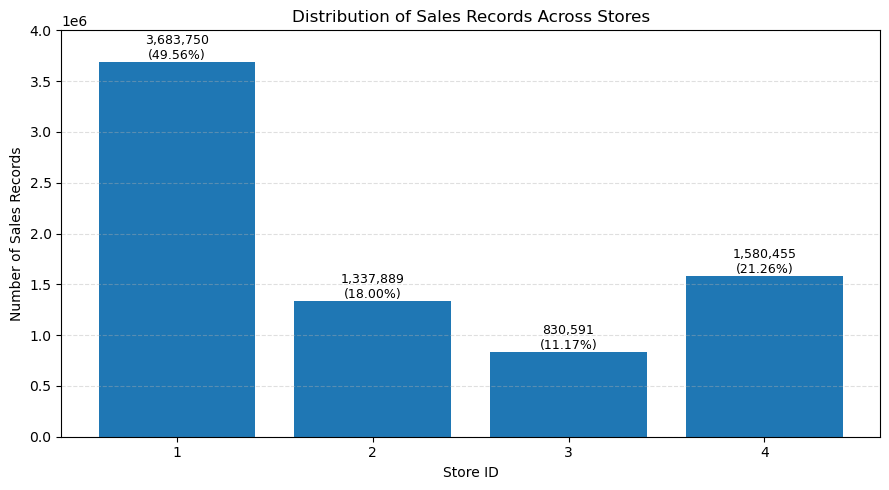

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Load only the store_id column from the original sales dataset
sales_store = pd.read_csv(
    "../data/raw/sales.csv",
    usecols=["store_id"]
)

# Calculate sales records for each store
store_summary = (
    sales_store["store_id"]
    .value_counts()
    .sort_index()
    .reset_index()
)

store_summary.columns = ["Store ID", "Sales Records"]

# Calculate percentage share
store_summary["Share (%)"] = (
    store_summary["Sales Records"] /
    store_summary["Sales Records"].sum() * 100
)

# Display summary table
display(
    store_summary.style.format({
        "Sales Records": "{:,.0f}",
        "Share (%)": "{:.2f}%"
    })
)

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    store_summary["Store ID"].astype(str),
    store_summary["Sales Records"]
)

# Add record counts and percentages above bars
for bar, count, percentage in zip(
    bars,
    store_summary["Sales Records"],
    store_summary["Share (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,.0f}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Distribution of Sales Records Across Stores")
plt.xlabel("Store ID")
plt.ylabel("Number of Sales Records")
plt.ylim(0, 4_000_000)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()